In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
from kalman.helpers import rainbow

Note: you may need to restart the kernel to use updated packages.


# Sensor Fusion with a Kalman Filter

This notebook fuses data from several sensors that track one hidden target. The sensors are
**asynchronous**: they report at different rates. The sensors are also **noisy**, each with its
own error level.

The Kalman update weights each sensor by its inverse covariance. Inverse covariance measures how
confident we are in a sensor's readings. This weighting means the fused estimate is more accurate
than any single sensor.

Different sensor rates need no special handling. When a sensor does not report at a step, the
engine marks that row as `NaN`. The engine then skips the update for that sensor, but still runs
the predict step.

`kalman.apps.fusion.SensorFusionModel` tracks a constant-velocity target. The state is
$x=[\,p,\ v\,]$, where $p$ is position and $v$ is velocity. You configure the model with a list of
`SensorSpec` objects. Each `SensorSpec` declares what the sensor observes, its noise level, and its
rate.

This notebook covers two setups:

- **Redundant sensors**: several sensors measure the same quantity (like a stereo camera and a
  lidar).
- **Complementary sensors**: sensors measure different quantities (like GPS position and IMU
  velocity).


## Step 1 — Set Up Three Redundant Position Sensors

This step uses three position sensors. Each sensor has a different quality and rate:

| sensor | noise (1σ) | rate |
|---|---|---|
| GPS | 3 m | 20 Hz |
| Radar | 2 m | 50 Hz |
| Lidar | 2.5 m | 25 Hz |

The framework stacks the sensor rows into the measurement matrix $H$. It stacks the sensor
variances into $R=\mathrm{diag}(\sigma_i^2)$.


In [2]:
from kalman.apps.fusion import SensorFusionModel, SensorSpec

fs = 50.0
sensors = [
    SensorSpec("GPS",   "position", uncertainty=3.0, rate=20),
    SensorSpec("Radar", "position", uncertainty=2.0, rate=50),
    SensorSpec("Lidar", "position", uncertainty=2.5, rate=25),
]
model = SensorFusionModel("target", sensors, fs=fs, process_uncertainty=2.0)
model.initial_state([0.0, 8.0])          # start at x=0 moving 8 m/s
print(f"state dim n={model.n}  measurement dim m={model.m}  (one row per sensor)")

state dim n=2  measurement dim m=3  (one row per sensor)


## Step 2 — Build the Asynchronous Stream and Fuse

`make_measurements` samples each sensor at its own rate. It adds each sensor's own noise. It then
interleaves the streams into one matrix at the base rate, using `NaN` to pad missing samples.

The figure below shows three things:

- The scatter of each sensor's raw readings.
- The fused estimate, with its $\pm\sigma$ band.
- The fused position $\sigma$, compared against every single-sensor $\sigma$.


measurement matrix: (400, 3)  NaN fraction per sensor: [0.6 0.  0.5]


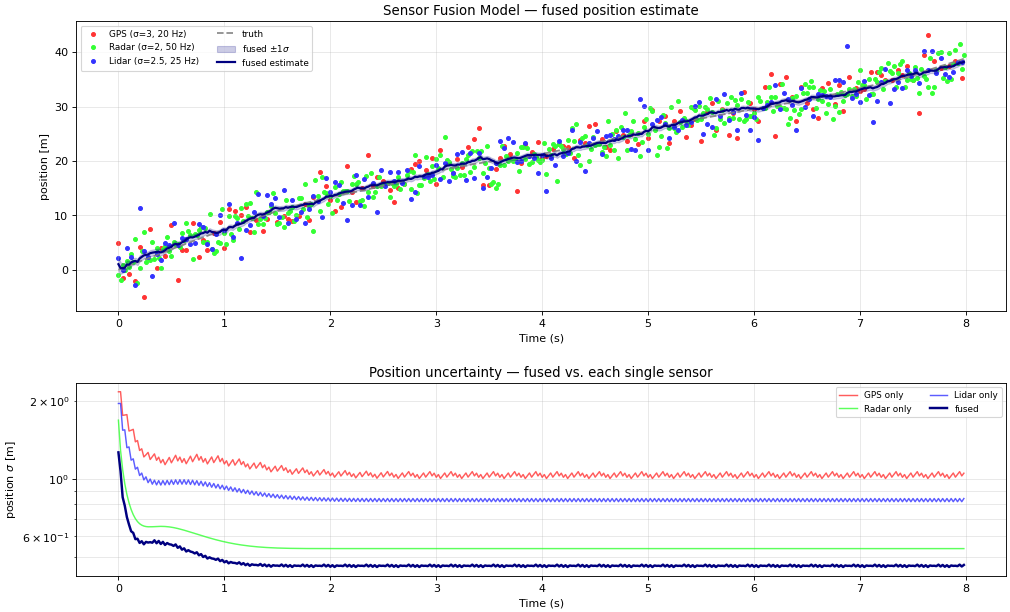

In [3]:
truth = model.sample(8.0)                       # clean constant-velocity ground truth
zk = model.make_measurements(truth, seed=1)     # multi-rate, NaN-padded
print("measurement matrix:", zk.shape, " NaN fraction per sensor:",
      np.round(np.isnan(zk).mean(axis=0), 2))

record = model.filter(zk)
model.plot(record, sample=truth, measurements=zk,
           meas=dict(alpha=1.0), colors=rainbow(len(model.sensors), l=0.6))
plt.show()

## Step 3 — Compare Fusion Against Each Single Sensor

To find the baseline for each sensor, filter it alone. Mask all other channels to `NaN` for that
run. This shows what each sensor could achieve on its own.

The fused estimate has a smaller steady-state variance than any single sensor. It also has a
smaller RMSE (root-mean-square error).


In [4]:
true_pos = truth.xk[:, 0]


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


print(f"{'sensor':<10}{'final sigma':>12}{'pos RMSE':>12}")
for i, sensor in enumerate(sensors):
    single_record = model.single_sensor_record(zk, i)
    single_sigma = np.sqrt(single_record.Pk[-1, 0, 0])
    single_rmse = rmse(single_record.xk[:, 0], true_pos)
    print(f"{sensor.name:<10}{single_sigma:>12.3f}{single_rmse:>12.3f}")

fused_sigma = np.sqrt(record.Pk[-1, 0, 0])
fused_rmse = rmse(record.xk[:, 0], true_pos)
print(f"{'FUSED':<10}{fused_sigma:>12.3f}{fused_rmse:>12.3f}")


sensor     final sigma    pos RMSE
GPS              1.054       0.787
Radar            0.538       0.518
Lidar            0.841       0.646
FUSED            0.465       0.399


## Step 4 — Fuse Complementary Sensors: Position and Velocity

This step uses a classic complementary filter. It fuses a slow, noisy GPS position with a fast,
precise IMU velocity. (IMU stands for inertial measurement unit; an encoder is a similar velocity
sensor.)

Neither sensor alone gives a good position estimate:

- GPS alone is too noisy.
- Integrating IMU velocity alone drifts over time.

Fused together, the position estimate is accurate.


GPS-only final pos sigma = 2.583 m
fused      final pos sigma = 0.912 m


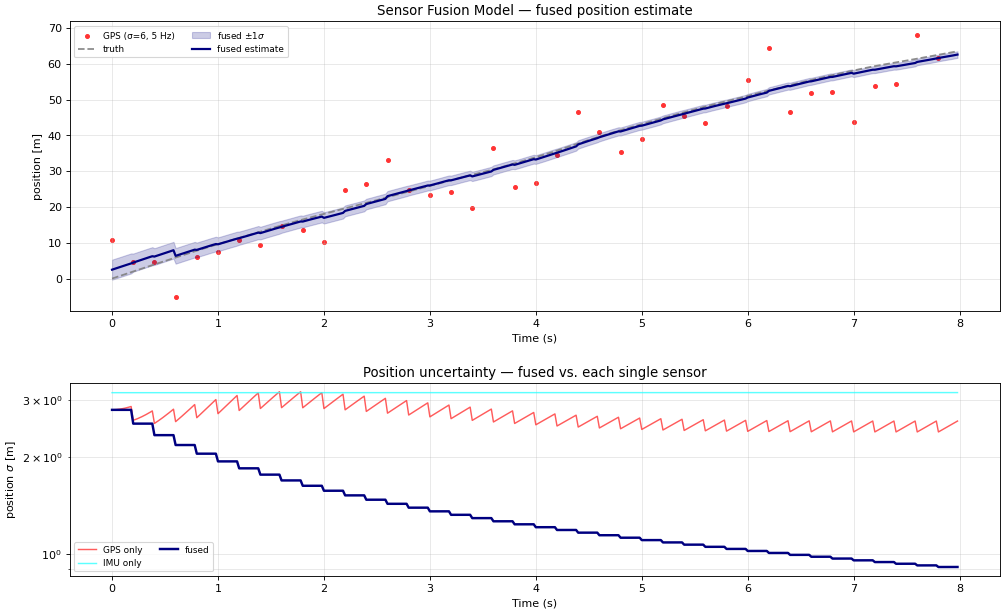

In [5]:
comp = SensorFusionModel("car", [
    SensorSpec("GPS", "position", uncertainty=6.0, rate=5),    # slow, noisy position
    SensorSpec("IMU", "velocity", uncertainty=0.3, rate=50),   # fast, precise velocity
], fs=50.0, process_uncertainty=1.0)
comp.initial_state([0.0, 10.0])

car_truth = comp.sample(8.0)
car_measurements = comp.make_measurements(car_truth, seed=3)
car_record = comp.filter(car_measurements)

gps_only = comp.single_sensor_record(car_measurements, 0)
gps_only_sigma = np.sqrt(gps_only.Pk[-1, 0, 0])
fused_sigma = np.sqrt(car_record.Pk[-1, 0, 0])
print(f"GPS-only final pos sigma = {gps_only_sigma:.3f} m")
print(f"fused      final pos sigma = {fused_sigma:.3f} m")

comp.plot(car_record, sample=car_truth, measurements=car_measurements,
          meas=dict(alpha=1.0), colors=rainbow(len(comp.sensors), l=0.6))
plt.show()


## Step 5 — Why Fusion Works: Inverse-Variance Weighting

Consider two position readings taken at the same time (synchronous). The optimal single-step
fusion of these readings is:

$$\hat x = \frac{\sigma_2^2 z_1 + \sigma_1^2 z_2}{\sigma_1^2+\sigma_2^2}$$

This fused estimate has variance:

$$\frac{1}{1/\sigma_1^2+1/\sigma_2^2}$$

This variance is always smaller than the variance of either input reading alone.

The Kalman update performs exactly this calculation. It generalises the calculation over time, and
across sensors that report at different rates.


In [6]:
sigma1, sigma2 = 3.0, 4.0

inv_var1 = 1.0 / sigma1 ** 2
inv_var2 = 1.0 / sigma2 ** 2
total_inv_var = inv_var1 + inv_var2

fused_var = 1.0 / total_inv_var
fused_sigma = fused_var ** 0.5
print(f"sigma1={sigma1}  sigma2={sigma2}  ->  fused sigma = {fused_sigma:.3f}  (< {min(sigma1, sigma2)})")

weight1 = inv_var1 / total_inv_var
weight2 = inv_var2 / total_inv_var
print("inverse-variance weights:", np.round([weight1, weight2], 3))


sigma1=3.0  sigma2=4.0  ->  fused sigma = 2.400  (< 3.0)
inverse-variance weights: [0.64 0.36]


## Takeaways

- Sensor fusion is a Kalman **measurement update** with a stacked $H$ matrix and a block-diagonal
  $R$ matrix.
- Asynchronous, multi-rate sensors need no special machinery. Missing rows are marked `NaN`, and
  the filter treats that step as predict-only.
- The fused estimate beats every single sensor. Redundant sensors shrink the variance.
  Complementary sensors observe different states (position and velocity). Together, they pin down
  the full state.
